# Rede de Administradores Compartilhados entre S.A. Abertas Brasileiras
**OPT108 – Grupo 7: Rede Societária e Concentração de Mercado (CNPJ)**

Pergunta de pesquisa (enunciado): *a densidade e o grau de intermediação da rede societária aumentaram nos últimos anos, sinalizando maior interlocking directorates e concentração corporativa?*

Pipeline:
1. `01_preparar_dados.py` baixa e filtra os dados abertos do CNPJ (snapshot 2024-09).
2. Este notebook monta o grafo bipartido pessoa ↔ empresa, projeta em empresa–empresa e calcula as métricas.

In [1]:
import pandas as pd, numpy as np, networkx as nx
import matplotlib.pyplot as plt
from collections import Counter
from networkx.algorithms import bipartite
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10})
SEED = 42
import os; os.makedirs('figuras', exist_ok=True); os.makedirs('tabelas', exist_ok=True)

## 1. Carregamento e limpeza

In [2]:
emp = pd.read_csv('data/empresas.csv', sep=';', dtype=str)
soc = pd.read_csv('data/socios.csv', sep=';', dtype=str)
est = pd.read_csv('data/estabelecimentos.csv', sep=';', dtype=str)

emp['capital_social'] = emp.capital_social.str.replace(',', '.').astype(float)
est = est[['cnpj', 'situacao', 'data_inicio', 'cnae_principal', 'uf']]
emp = emp.merge(est, on='cnpj', how='left')

print('S.A. abertas no cadastro:', len(emp))
print(emp.situacao.map({'01':'nula','02':'ativa','03':'suspensa','04':'inapta','08':'baixada'}).value_counts())

S.A. abertas no cadastro: 3169
situacao
baixada     1629
ativa       1082
inapta       438
suspensa      15
nula           5
Name: count, dtype: int64


In [3]:
# Mantém só empresas ATIVAS (situação 02)
ativas = set(emp.loc[emp.situacao == '02', 'cnpj'])
soc = soc[soc.cnpj.isin(ativas)].copy()

# Tabela de qualificações (Receita Federal) mais comuns no QSA de S.A.
QUAL = {'05':'Administrador','08':'Conselheiro de Administração','10':'Diretor','16':'Presidente',
        '22':'Sócio','28':'Sócio-Gerente','37':'Sócio PJ no exterior','49':'Sócio-Administrador',
        '63':'Cotas em Tesouraria','71':'Conselheiro (exterior)','72':'Diretor (exterior)'}
soc['qualificacao_nome'] = soc.qualificacao.map(QUAL).fillna('Outra')

# Identificador da pessoa: o CPF vem mascarado (***123456**), então usamos nome + CPF mascarado.
# Para sócio PJ o documento é o CNPJ completo.
soc['pessoa'] = soc.tipo_socio + '|' + soc.nome_socio.str.strip().str.upper() + '|' + soc.doc_socio.fillna('')
soc['data_entrada'] = pd.to_datetime(soc.data_entrada, format='%Y%m%d', errors='coerce')

# Remove duplicatas (mesma pessoa listada 2x na mesma empresa) e vínculos sem nome
antes = len(soc)
soc = soc.dropna(subset=['nome_socio']).sort_values('data_entrada').drop_duplicates(['cnpj', 'pessoa'])
print(f'Vínculos: {antes} -> {len(soc)} após limpeza')
print('Empresas ativas com QSA:', soc.cnpj.nunique(), '| Pessoas distintas:', soc.pessoa.nunique())
soc.qualificacao_nome.value_counts()

Vínculos: 5443 -> 5443 após limpeza
Empresas ativas com QSA: 1035 | Pessoas distintas: 4513


qualificacao_nome
Diretor                         3139
Conselheiro de Administração    1525
Presidente                       680
Administrador                     84
Cotas em Tesouraria                5
Sócio                              4
Sócio PJ no exterior               3
Sócio-Administrador                1
Sócio-Gerente                      1
Outra                              1
Name: count, dtype: int64

## 2. Grafo bipartido e projeção
**Modelagem.** Vértice = empresa (S.A. aberta ativa). Aresta = as duas empresas têm pelo menos um administrador (diretor, conselheiro ou presidente) em comum.
- **Não direcionado**: dividir um administrador é uma relação simétrica, e o QSA não diz qual empresa indicou a pessoa.
- **Ponderado**: peso = nº de administradores em comum. Dividir 1 conselheiro é diferente de dividir a diretoria inteira (típico de empresas do mesmo grupo, o que importa pra QP3).
- Empresas sem nenhum administrador em comum ficam como **vértices isolados** de propósito, porque fazem parte da população e entram na densidade e na fração de empresas interligadas.

In [4]:
B = nx.Graph()
B.add_nodes_from(soc.cnpj.unique(), bipartite=0)
B.add_nodes_from(soc.pessoa.unique(), bipartite=1)
B.add_edges_from(zip(soc.cnpj, soc.pessoa))

empresas_nos = set(soc.cnpj)
# Projeção unipartida: empresas ligadas se dividem >= 1 administrador; peso = nº de administradores em comum
G = bipartite.weighted_projected_graph(B, empresas_nos)
nome = emp.set_index('cnpj').razao_social.to_dict()
nx.set_node_attributes(G, nome, 'nome')

# Pessoas que fazem a ponte (estão em 2+ empresas)
boards = soc.groupby('pessoa').cnpj.nunique()
print('Pessoas em 2+ empresas (interlockers):', (boards >= 2).sum(), f'({(boards>=2).mean():.1%})')
print('Empresas com pelo menos 1 interlock:', sum(1 for n in G if G.degree(n) > 0), 'de', G.number_of_nodes())

Pessoas em 2+ empresas (interlockers): 558 (12.4%)
Empresas com pelo menos 1 interlock: 439 de 1035


## 3. Estatísticas descritivas

In [5]:
def resumo(G):
    lcc = G.subgraph(max(nx.connected_components(G), key=len))
    return {
        '|V|': G.number_of_nodes(), '|E|': G.number_of_edges(),
        'densidade': nx.density(G), 'grau médio': 2*G.number_of_edges()/G.number_of_nodes(),
        'isolados': nx.number_of_isolates(G), 'componentes': nx.number_connected_components(G),
        '|V| do maior componente': lcc.number_of_nodes(),
        '% no maior componente': lcc.number_of_nodes()/G.number_of_nodes(),
        'clustering médio': nx.average_clustering(G),
        'transitividade': nx.transitivity(G),
        'dist. média (maior comp.)': nx.average_shortest_path_length(lcc),
        'diâmetro (maior comp.)': nx.diameter(lcc),
    }
desc = pd.Series(resumo(G)).to_frame('valor')
desc.to_csv('tabelas/estatisticas_descritivas.csv'); desc

,valor
|V|,1035.000000
|E|,706.000000
densidade,0.001319
grau médio,1.364251
isolados,596.000000
componentes,689.000000
|V| do maior componente,121.000000
% no maior componente,0.116908
clustering médio,0.208738
transitividade,0.814864


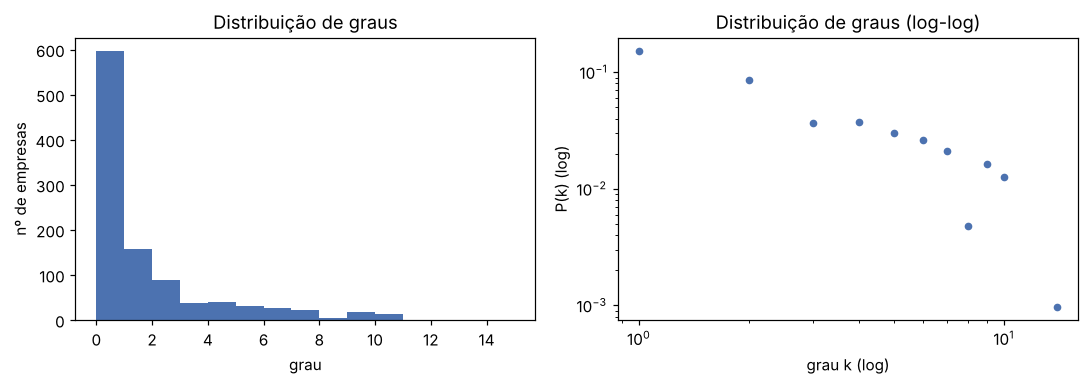

In [6]:
graus = np.array([d for _, d in G.degree()])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(graus, bins=range(0, graus.max()+2), color='#4C72B0')
ax[0].set(xlabel='grau', ylabel='nº de empresas', title='Distribuição de graus')
cont = Counter(graus[graus > 0]); k = np.array(sorted(cont)); pk = np.array([cont[x] for x in k]) / len(graus)
ax[1].loglog(k, pk, 'o', color='#4C72B0', ms=4)
ax[1].set(xlabel='grau k (log)', ylabel='P(k) (log)', title='Distribuição de graus (log-log)')
plt.tight_layout(); plt.savefig('figuras/distribuicao_graus.png'); plt.show()

## 4. Centralidades

In [7]:
lcc_nodes = max(nx.connected_components(G), key=len)
L = G.subgraph(lcc_nodes).copy()

# Para caminhos, peso maior = ligação mais forte = distância menor
for u, v, d in G.edges(data=True):
    d['dist'] = 1 / d['weight']

cent = pd.DataFrame({
    'grau': dict(G.degree()),
    'grau_ponderado': dict(G.degree(weight='weight')),
    'intermediacao': nx.betweenness_centrality(G, weight='dist', normalized=True),
    'proximidade': nx.closeness_centrality(G, distance='dist'),
    'pagerank': nx.pagerank(G, weight='weight'),
})
cent['autovetor'] = pd.Series(nx.eigenvector_centrality_numpy(L, weight='weight'))
cent['autovetor'] = cent.autovetor.fillna(0)
cent['nome'] = cent.index.map(nome)
cent['cnae'] = cent.index.map(emp.set_index('cnpj').cnae_principal)
cent.sort_values('intermediacao', ascending=False).head(15)

,grau,grau_ponderado,intermediacao,proximidade,pagerank,autovetor,nome,cnae
02846056,14,21,0.004888,0.034391,0.004629,1.400217e-06,CCR S.A.,6462000
61532644,6,12,0.004763,0.034434,0.003131,1.366332e-06,ITAUSA S.A.,6462000
91983056,4,4,0.004737,0.029708,0.001671,9.310482e-03,KEPLER WEBER SA,6462000
03847461,7,18,0.004550,0.026341,0.002580,2.653254e-01,BRADESPAR S.A.,6462000
89086144,4,6,0.003593,0.031854,0.002209,3.465439e-05,RANDON SA IMPLEMENTOS E PARTICIPACOES,2930101
12091809,4,8,0.003492,0.029852,0.002762,4.528991e-07,3R PETROLEUM OLEO E GAS S.A.,0600001
42150391,5,5,0.003367,0.022736,0.001711,5.596220e-10,BRASKEM S.A,2021500
88610126,2,4,0.003363,0.030843,0.001579,3.291112e-04,FRAS-LE SA,2943300
08827501,8,16,0.002973,0.031119,0.003607,1.279028e-07,AEGEA SANEAMENTO E PARTICIPACOES S.A.,6462000
60872504,8,16,0.002897,0.032032,0.004553,2.092434e-07,ITAU UNIBANCO HOLDING S.A.,6431000


In [8]:
top = {}
for m in ['grau', 'intermediacao', 'proximidade', 'pagerank', 'autovetor']:
    top[m] = cent.sort_values(m, ascending=False).head(10).nome.str[:45].tolist()
top = pd.DataFrame(top, index=range(1, 11))
top.to_csv('tabelas/top10_centralidades.csv'); top

,grau,intermediacao,proximidade,pagerank,autovetor
1,CCR S.A.,CCR S.A.,LINHAS DE XINGU TRANSMISSORA DE ENERGIA S.A.,BANCO BRADESCO S.A.,BANCO BRADESCO S.A.
2,ARTERIS S.A.,ITAUSA S.A.,LINHAS DE MACAPA TRANSMISSORA DE ENERGIA S.A.,CCR S.A.,BRADESCO LEASING S.A. - ARRENDAMENTO MERCANTI
3,ENERGISA MINAS RIO - DISTRIBUIDORA DE ENERGIA,KEPLER WEBER SA,ENERGISA SUL-SUDESTE - DISTRIBUIDORA DE ENERG,ITAU UNIBANCO HOLDING S.A.,NCF PARTICIPACOES S.A.
4,ENERGISA S/A,BRADESPAR S.A.,ITAUSA S.A.,HIDROVIAS DO BRASIL S.A.,BRADESPAR S.A.
5,ENERGISA MATO GROSSO - DISTRIBUIDORA DE ENERG,RANDON SA IMPLEMENTOS E PARTICIPACOES,CCR S.A.,BRADESCO LEASING S.A. - ARRENDAMENTO MERCANTI,ODONTOPREV S.A.
6,ENERGISA PARAIBA - DISTRIBUIDORA DE ENERGIA S,3R PETROLEUM OLEO E GAS S.A.,ENERGISA MATO GROSSO DO SUL - DISTRIBUIDORA D,CYRELA BRAZIL REALTY S.A. EMPREENDIMENTOS E P,CIELO S.A - INSTITUICAO DE PAGAMENTO
7,LINHAS DE MACAPA TRANSMISSORA DE ENERGIA S.A.,BRASKEM S.A,ENERGISA SERGIPE - DISTRIBUIDORA DE ENERGIA S,EQUATORIAL S.A.,SOLVI ESSENCIS AMBIENTAL S.A.
8,EQUATORIAL S.A.,FRAS-LE SA,ENERGISA MATO GROSSO - DISTRIBUIDORA DE ENERG,GERDAU S.A.,EQUATORIAL S.A.
9,LINHAS DE XINGU TRANSMISSORA DE ENERGIA S.A.,AEGEA SANEAMENTO E PARTICIPACOES S.A.,ENERGISA PARAIBA - DISTRIBUIDORA DE ENERGIA S,AEGEA SANEAMENTO E PARTICIPACOES S.A.,COMPANHIA ESTADUAL DE DISTRIBUICAO DE ENERGIA
10,ENERGISA SERGIPE - DISTRIBUIDORA DE ENERGIA S,ITAU UNIBANCO HOLDING S.A.,DEXCO S.A,NCF PARTICIPACOES S.A.,EQUATORIAL MARANHAO DISTRIBUIDORA DE ENERGIA


In [9]:
# Correlação de Spearman entre as métricas (empresas do maior componente)
cent.loc[list(lcc_nodes), ['grau','intermediacao','proximidade','pagerank','autovetor']].corr('spearman').round(2)

,grau,intermediacao,proximidade,pagerank,autovetor
grau,1.00,0.47,0.28,0.79,0.09
intermediacao,0.47,1.00,0.39,0.44,0.23
proximidade,0.28,0.39,1.00,0.31,0.39
pagerank,0.79,0.44,0.31,1.00,0.09
autovetor,0.09,0.23,0.39,0.09,1.00


In [10]:
# Os administradores que mais conectam empresas (nº de S.A. abertas em que aparecem)
top_pessoas = (soc.groupby('pessoa').agg(empresas=('cnpj', 'nunique'), cargos=('qualificacao_nome', lambda s: ', '.join(sorted(set(s)))))
               .sort_values('empresas', ascending=False).head(15))
top_pessoas.index = top_pessoas.index.str.split('|').str[1]
top_pessoas

,empresas,cargos
pessoa,,
MAURICIO PEREZ BOTELHO,11,Diretor
NILTON LEONARDO FERNANDES DE OLIVEIRA,10,"Diretor, Presidente"
ANDRE GIAVINA BIANCHI,9,"Diretor, Presidente"
DANIELE ARAUJO SALOMAO CASTELO,9,"Conselheiro de Administração, Diretor"
GIORELI DE SOUSA FILHO,9,"Conselheiro de Administração, Diretor"
JOAO CARLOS FALBO MANSUR,9,"Conselheiro de Administração, Presidente"
FERNANDO HAMAOUI,8,"Diretor, Presidente"
LEONARDO DE SOUZA CARVALHO,8,Diretor
RICARDO LAHAM,8,Diretor


## 5. Comunidades (Louvain)

In [11]:
comms = nx.community.louvain_communities(L, weight='weight', seed=SEED)
comms = sorted(comms, key=len, reverse=True)
Q = nx.community.modularity(L, comms, weight='weight')
print(f'{len(comms)} comunidades no maior componente | modularidade Q = {Q:.3f}')

comm_de = {n: i for i, c in enumerate(comms) for n in c}
cent['comunidade'] = cent.index.map(comm_de)

linhas = []
for i, c in enumerate(comms[:12]):
    sub = cent.loc[list(c)]
    principais = sub.sort_values('pagerank', ascending=False).nome.str[:35].head(4).tolist()
    cnae2 = sub.cnae.str[:2].value_counts()
    linhas.append({'comunidade': i, 'tamanho': len(c),
                   'divisão CNAE mais comum': f"{cnae2.index[0]} ({cnae2.iloc[0]/len(c):.0%})",
                   'empresas mais centrais (PageRank)': ' | '.join(principais)})
tab_comm = pd.DataFrame(linhas); tab_comm.to_csv('tabelas/comunidades.csv', index=False)
pd.set_option('display.max_colwidth', 200); tab_comm

16 comunidades no maior componente | modularidade Q = 0.846


,comunidade,tamanho,divisão CNAE mais comum,empresas mais centrais (PageRank)
0,0,12,64 (58%),HIDROVIAS DO BRASIL S.A. | SERENA ENERGIA S.A. | RANDON SA IMPLEMENTOS E PARTICIPACO | KEPLER WEBER SA
1,1,11,52 (55%),CCR S.A. | CONCESSIONARIA DE RODOVIA SUL - MAT | CONCESSIONARIA DE RODOVIAS DO OESTE | CONCESSIONARIA DO SISTEMA ANHANGUER
2,2,10,35 (60%),EQUATORIAL S.A. | COMPANHIA ESTADUAL DE DISTRIBUICAO | EQUATORIAL MARANHAO DISTRIBUIDORA D | EQUATORIAL TRANSMISSORA 8 SPE S.A.
3,3,10,64 (80%),SANTOS BRASIL PARTICIPACOES S.A. | NUMERAL 80 PARTICIPACOES S/A | PROMPT PARTICIPACOES S.A. | GAMA PARTICIPACOES S.A
4,4,10,64 (30%),IRANI PAPEL E EMBALAGEM S.A. | COMPANHIA HABITASUL DE PARTICIPACOE | 3R PETROLEUM OLEO E GAS S.A. | LOJAS RENNER S.A.
5,5,10,64 (50%),ITAU UNIBANCO HOLDING S.A. | ITAUSA S.A. | NATURA &CO HOLDING S.A. | DIBENS LEASING S/A - ARRENDAMENTO M
6,6,9,64 (56%),BANCO BRADESCO S.A. | BRADESCO LEASING S.A. - ARRENDAMENT | NCF PARTICIPACOES S.A. | BRADESPAR S.A.
7,7,8,35 (25%),LIGHT S/A - EM RECUPERACAO JUDICIAL | LIGHT SERVICOS DE ELETRICIDADE S A | LIGHT ENERGIA S.A | KLABIN S.A.
8,8,7,52 (71%),INVESTIMENTOS E PARTICIPACOES EM IN | CONCESSIONARIA BR-040 S.A. | LINHA AMARELA S/A - LAMSA | CONCESSIONARIA RIO TERESOPOLIS S A
9,9,7,77 (43%),"SIMPAR S.A. | MOVIDA PARTICIPACOES S.A. | MOVIDA LOCACAO DE VEICULOS S.A. | VAMOS LOCACAO DE CAMINHOES, MAQUINA"


## 6. Visualização

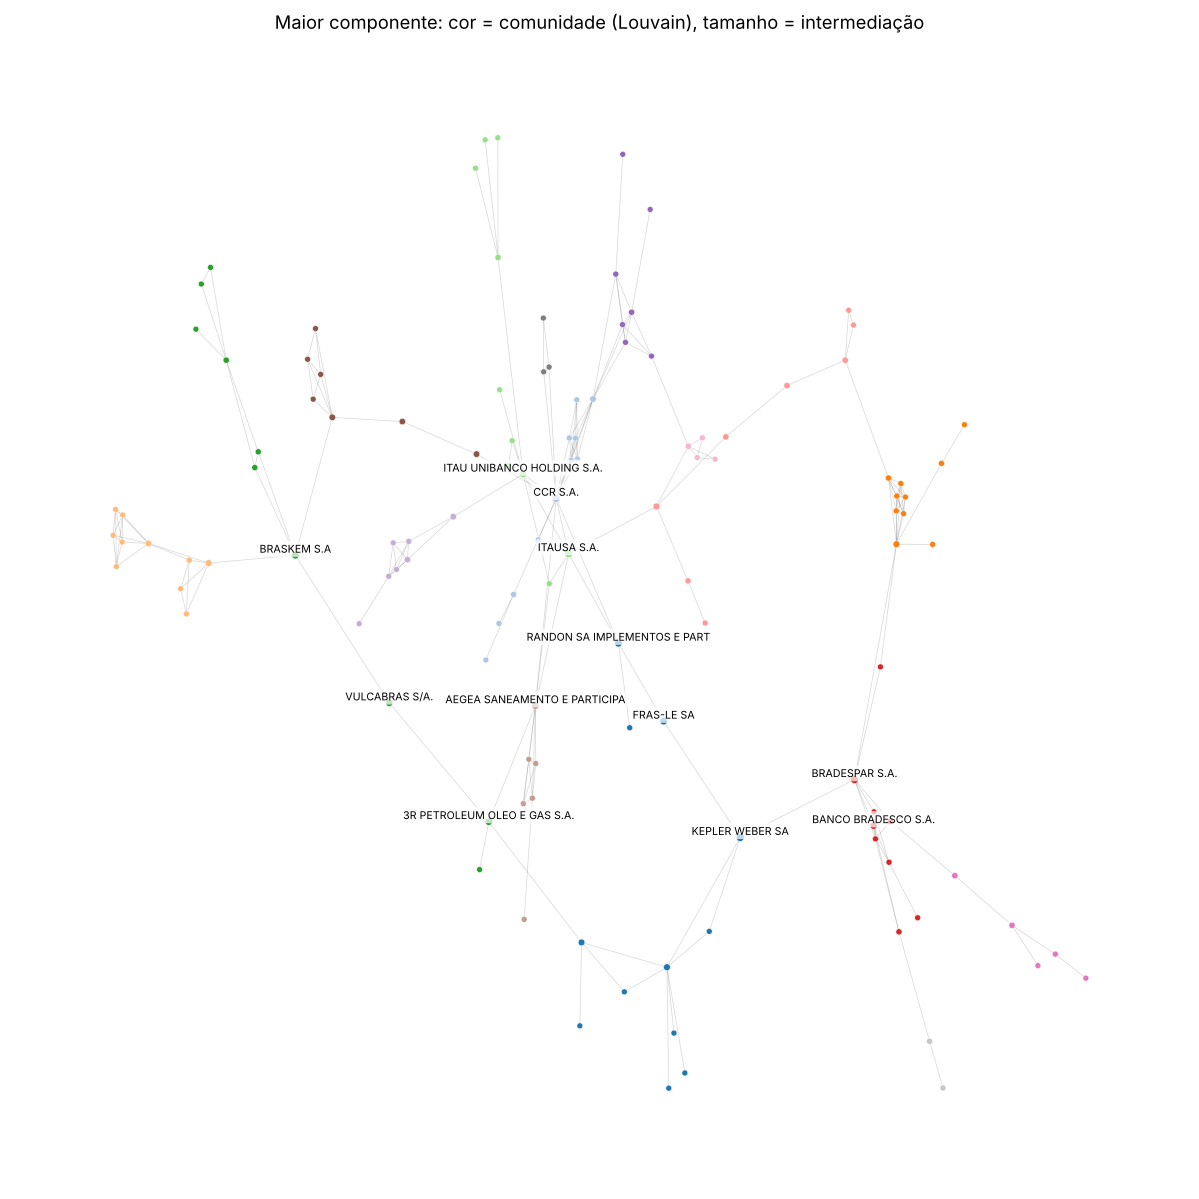

In [12]:
pos = nx.spring_layout(L, weight='weight', seed=SEED, k=0.12, iterations=200)
cores = plt.cm.tab20.colors
fig, ax = plt.subplots(figsize=(11, 11))
bet = cent.intermediacao
nx.draw_networkx_edges(L, pos, alpha=0.15, width=0.5, ax=ax)
nx.draw_networkx_nodes(L, pos, ax=ax,
    node_color=[cores[comm_de[n] % 20] for n in L],
    node_size=[15 + 2500 * bet[n] for n in L], linewidths=0.3, edgecolors='white')
for n in bet.loc[list(L)].sort_values(ascending=False).head(12).index:
    ax.annotate(nome[n][:28], pos[n], fontsize=7, ha='center', va='bottom',
                bbox=dict(boxstyle='round,pad=0.15', fc='white', alpha=0.7, lw=0))
ax.set_title('Maior componente: cor = comunidade (Louvain), tamanho = intermediação')
ax.axis('off'); plt.tight_layout(); plt.savefig('figuras/rede_comunidades.png', bbox_inches='tight'); plt.show()

## 7. Evolução temporal (aproximação)
O QSA é um **retrato de set/2024**: só aparecem os administradores atuais. Reconstruímos a rede de cada ano usando
apenas vínculos com `data_entrada <= ano`. **Viés de sobrevivência**: quem saiu da empresa antes de 2024 não aparece,
então anos antigos ficam sub-representados e as métricas tendem a crescer por construção. Por isso, além dos valores
absolutos, olhamos métricas relativas ao tamanho (fração de empresas interligadas, % no maior componente).

In [13]:
anos = range(2010, 2025)
evol = []
for ano in anos:
    s = soc[soc.data_entrada.dt.year <= ano]
    b = nx.Graph(); b.add_edges_from(zip(s.cnpj, s.pessoa))
    g = bipartite.weighted_projected_graph(b, set(s.cnpj))
    lcc = max(nx.connected_components(g), key=len)
    bt = nx.betweenness_centrality(g, normalized=True)
    evol.append({'ano': ano, '|V|': g.number_of_nodes(), '|E|': g.number_of_edges(),
                 'densidade': nx.density(g),
                 'grau médio': 2*g.number_of_edges()/g.number_of_nodes(),
                 'frac. empresas interligadas': 1 - nx.number_of_isolates(g)/g.number_of_nodes(),
                 'frac. no maior componente': len(lcc)/g.number_of_nodes(),
                 'intermediação média': np.mean(list(bt.values())),
                 'intermediação máxima': max(bt.values())})
evol = pd.DataFrame(evol).set_index('ano'); evol.to_csv('tabelas/evolucao_temporal.csv'); evol.round(6)

,|V|,|E|,densidade,grau médio,frac. empresas interligadas,frac. no maior componente,intermediação média,intermediação máxima
ano,,,,,,,,
2010,387,54,0.000723,0.279070,0.131783,0.018088,0.000000,0.000000
2011,412,57,0.000673,0.276699,0.126214,0.016990,0.000000,0.000000
2012,431,59,0.000637,0.273782,0.122970,0.016241,0.000000,0.000000
2013,463,60,0.000561,0.259179,0.118790,0.015119,0.000000,0.000000
2014,490,78,0.000651,0.318367,0.130612,0.014286,0.000000,0.000000
2015,539,83,0.000572,0.307978,0.131725,0.012987,0.000000,0.000000
2016,588,101,0.000585,0.343537,0.136054,0.013605,0.000000,0.000006
2017,638,126,0.000620,0.394984,0.161442,0.014107,0.000000,0.000010
2018,701,156,0.000636,0.445078,0.189729,0.012839,0.000000,0.000012


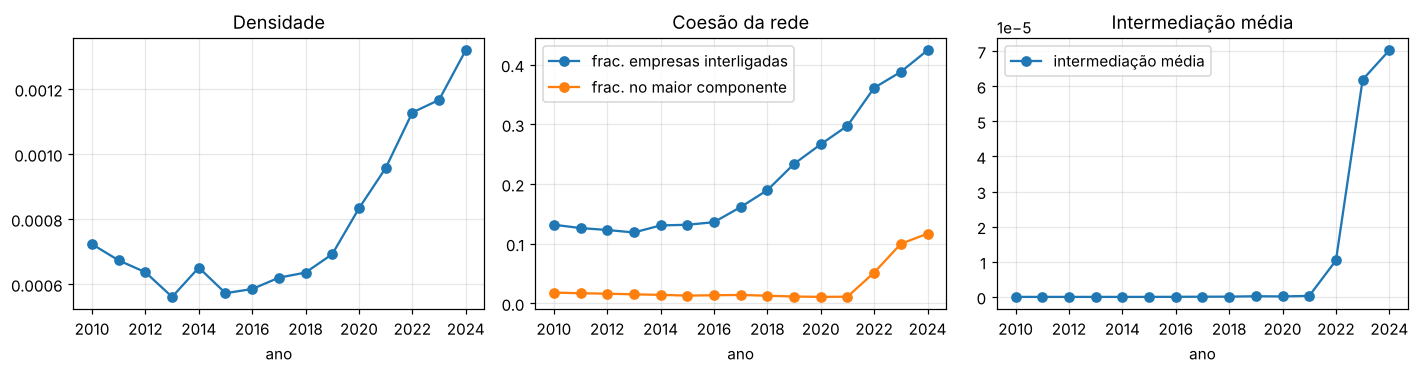

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
evol['densidade'].plot(ax=ax[0], marker='o', title='Densidade')
evol[['frac. empresas interligadas', 'frac. no maior componente']].plot(ax=ax[1], marker='o', title='Coesão da rede')
evol[['intermediação média']].plot(ax=ax[2], marker='o', title='Intermediação média')
for a in ax: a.set_xlabel('ano'); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig('figuras/evolucao_temporal.png'); plt.show()

## 8. Exporta para o Gephi (opcional)

In [15]:
for n in G:
    G.nodes[n].update({k: (float(v) if isinstance(v, (int, float, np.floating, np.integer)) else str(v))
                       for k, v in cent.loc[n].items() if pd.notna(v)})
for u, v, d in G.edges(data=True): d.pop('dist', None)
nx.write_gexf(G, 'rede_sa_abertas.gexf'); cent.to_csv('tabelas/centralidades_todas.csv')